In [12]:
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import scipy.sparse as sp

In [15]:
def wczytaj_mtx(filepath):
    G = nx.Graph()
    with open(filepath, "r", encoding="utf-8") as f:
        header = False
        for line in f:
            if line.startswith("%") or not line.strip():
                continue
            parts = line.strip().split()
            if not header and len(parts) == 3:
                header = True
                continue
            if len(parts) >= 2:
                u, v = int(parts[0]), int(parts[1])
                if u != v:
                    G.add_edge(u, v)
    return G
PLIK = "ca-GrQc.mtx"
graf = wczytaj_mtx(PLIK)

In [21]:
def przetworz_macierze(G):
    V = G.number_of_nodes()
    E = G.number_of_edges()

    print("--- PUNKT 1: Generowanie macierzy i zapis do CSV ---")

    A = sp.lil_matrix((V, V), dtype=int)
    for u, v in G.edges():
        A[u - 1, v - 1] = 1
        A[v - 1, u - 1] = 1

    np.savetxt("macierz_sasiedztwa.csv", A.toarray(), fmt="%d", delimiter=",")
    print(" -> Zapisano: macierz_sasiedztwa.csv")

    M = sp.lil_matrix((V, E), dtype=int)
    for edge_idx, (u, v) in enumerate(G.edges()):
        M[u - 1, edge_idx] = 1
        M[v - 1, edge_idx] = 1

    np.savetxt("macierz_incydencji.csv", M.toarray(), fmt="%d", delimiter=",")
    print(" -> Zapisano: macierz_incydencji.csv")

    print("\n--- PUNKT 2: Odtwarzanie grafów z CSV ---")

    A_loaded = np.loadtxt("macierz_sasiedztwa.csv", delimiter=",", dtype=int)
    G_from_A = nx.Graph()

    rows, cols = np.where(np.triu(A_loaded, k=1) == 1)
    for i, j in zip(rows, cols):
        G_from_A.add_edge(i + 1, j + 1)

    M_loaded = np.loadtxt("macierz_incydencji.csv", delimiter=",", dtype=int)
    G_from_M = nx.Graph()

    r_idx, c_idx = np.where(M_loaded == 1)
    krawedzie = defaultdict(list)
    for r, c in zip(r_idx, c_idx):
        krawedzie[c].append(r + 1)

    for endpoints in krawedzie.values():
        if len(endpoints) == 2:
            G_from_M.add_edge(endpoints[0], endpoints[1])

    print(
        f"Odtworzony z A: {G_from_A.number_of_nodes()} węzłów, {G_from_A.number_of_edges()} krawędzi."
    )
    print(
        f"Odtworzony z M: {G_from_M.number_of_nodes()} węzłów, {G_from_M.number_of_edges()} krawędzi."
    )
    return G_from_A, G_from_M
G_from_A,G_from_M = przetworz_macierze(graf)

--- PUNKT 1: Generowanie macierzy i zapis do CSV ---
 -> Zapisano: macierz_sasiedztwa.csv
 -> Zapisano: macierz_incydencji.csv

--- PUNKT 2: Odtwarzanie grafów z CSV ---
Odtworzony z A: 4158 węzłów, 13422 krawędzi.
Odtworzony z M: 4158 węzłów, 13422 krawędzi.



--- PUNKT 3: Generowanie wizualizacji grafu ---


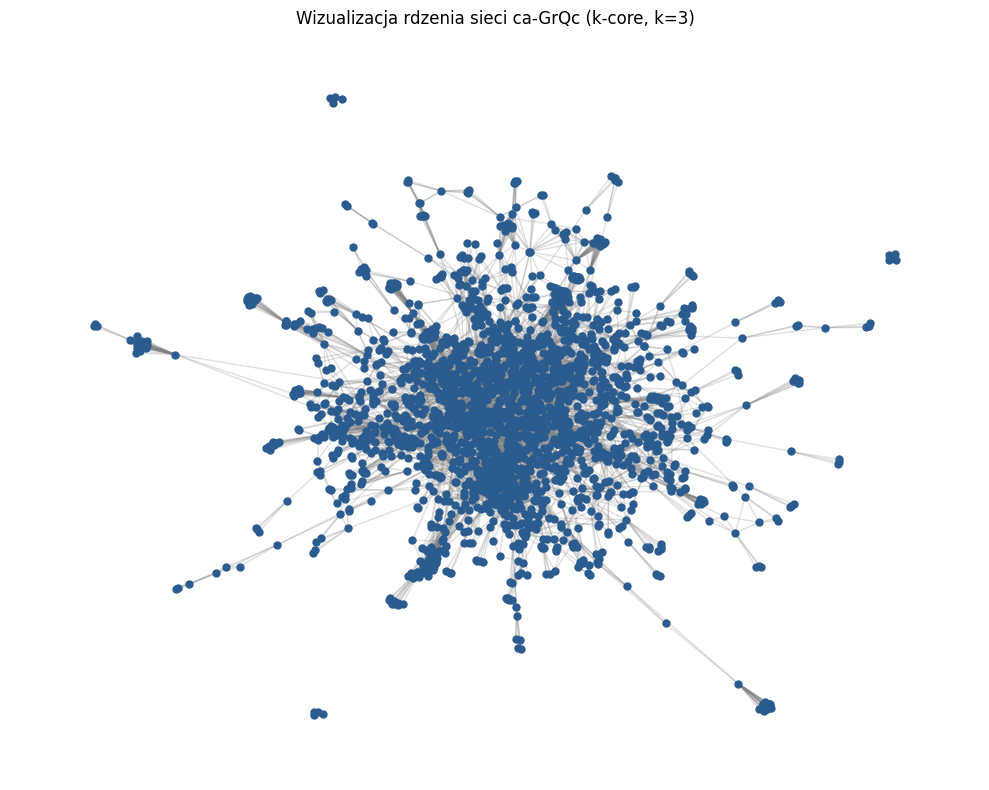


--- PUNKT 3: Generowanie wizualizacji grafu ---


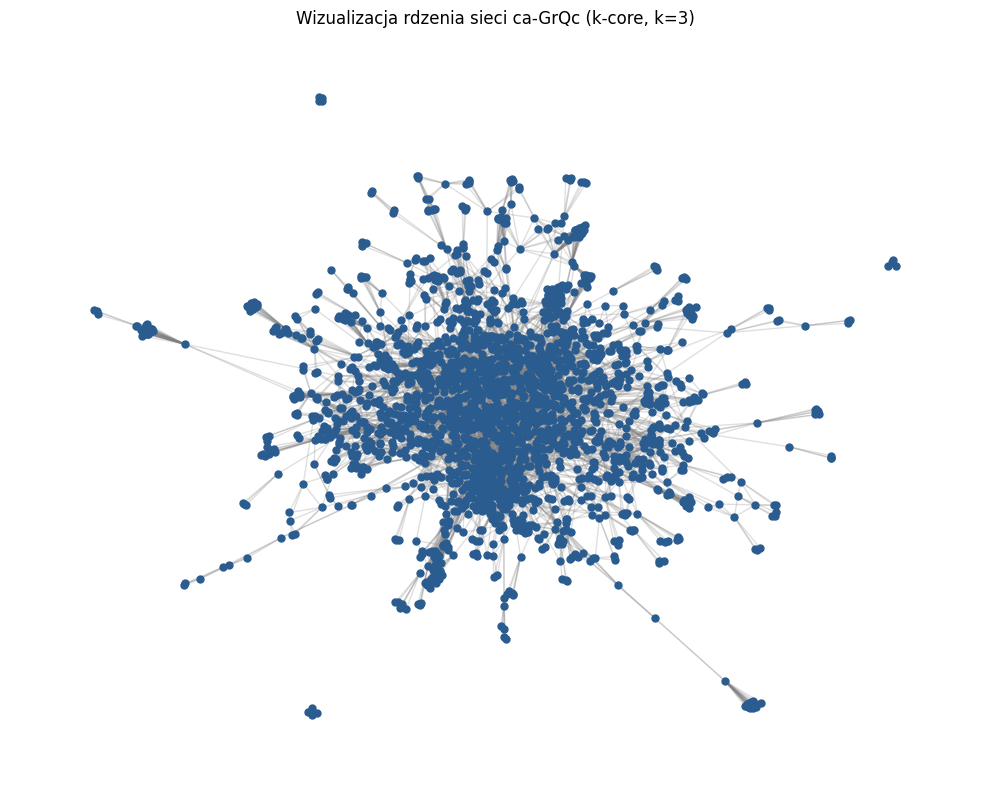


--- PUNKT 3: Generowanie wizualizacji grafu ---


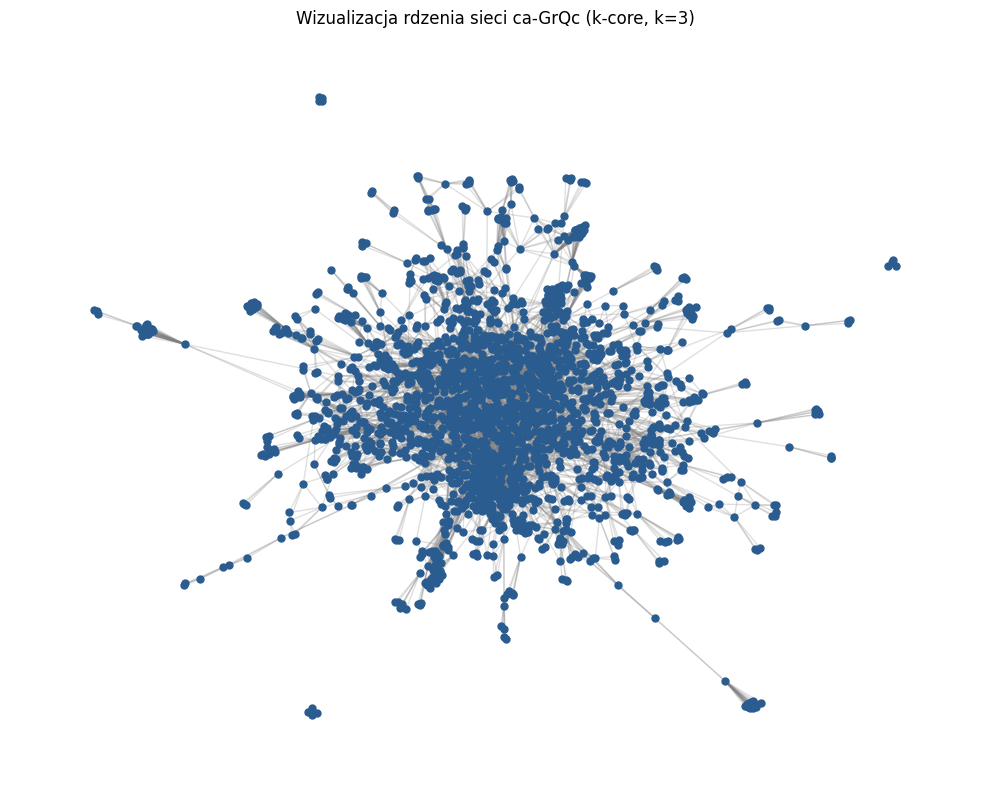

In [26]:

def wizualizuj_graf(G):
    print("\n--- PUNKT 3: Generowanie wizualizacji grafu ---")

    G_core = nx.k_core(G, k=3)
    pos = nx.spring_layout(G_core, seed=42)

    plt.figure(figsize=(10, 8))
    nx.draw_networkx_nodes(G_core, pos, node_size=25, node_color="#2b5c8f")
    nx.draw_networkx_edges(G_core, pos, alpha=0.25, edge_color="gray")
    plt.title("Wizualizacja rdzenia sieci ca-GrQc (k-core, k=3)")
    plt.axis("off")
    plt.tight_layout()
    plt.savefig("wizualizacja_grafu.png", dpi=300)
    plt.show()
wizualizuj_graf(graf)
wizualizuj_graf(G_from_A)
wizualizuj_graf(G_from_M)


--- PUNKT 4: Wyznaczanie wskaźników strukturalnych ---
Gęstość grafu (Density): 0.001553
Średnica grafu dla LCC (Diameter): 17


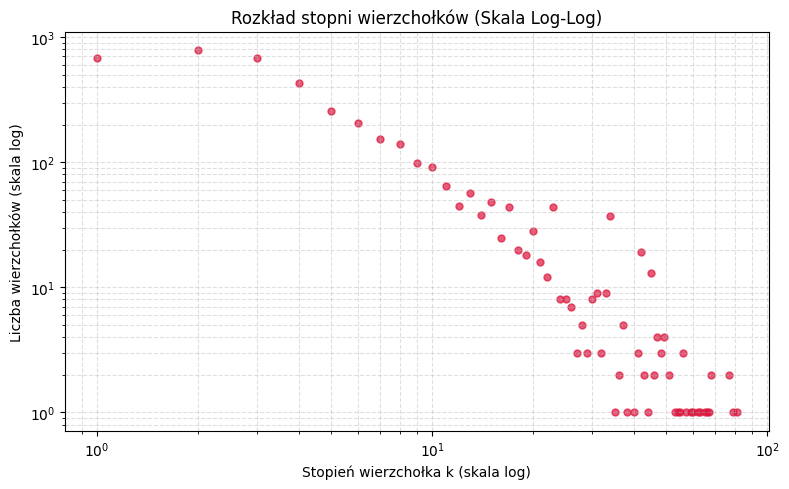

In [23]:
def oblicz_wskazniki(G):
    print("\n--- PUNKT 4: Wyznaczanie wskaźników strukturalnych ---")


    density = nx.density(G)
    print(f"Gęstość grafu (Density): {density:.6f}")


    lcc_nodes = max(nx.connected_components(G), key=len)
    G_lcc = G.subgraph(lcc_nodes)
    diameter = nx.diameter(G_lcc)
    print(f"Średnica grafu dla LCC (Diameter): {diameter}")


    degrees = [deg for node, deg in G.degree()]
    degree_counts = Counter(degrees)

    x = list(degree_counts.keys())
    y = list(degree_counts.values())

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, color="crimson", alpha=0.7, s=25)
    plt.xscale("log")
    plt.yscale("log")
    plt.title("Rozkład stopni wierzchołków (Skala Log-Log)")
    plt.xlabel("Stopień wierzchołka k (skala log)")
    plt.ylabel("Liczba wierzchołków (skala log)")
    plt.grid(True, which="both", ls="--", alpha=0.4)
    plt.tight_layout()
    plt.savefig("rozklad_stopni.png", dpi=300)
    plt.show()

oblicz_wskazniki(graf)